# PromptPiper — Visualizations

Organized by research question (see §Objectives in the paper):

1. **RQ1** — Trade-off between prompt compression and task performance
2. **RQ2** — How PromptPiper compares to existing baselines
3. **RQ3** — Cost and convergence characteristics
4. **RQ4** — Patterns in compression strategies and transferability

Missing results are skipped gracefully — re-run when new experiments complete.

In [31]:
import json
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

RESULTS_DIR = Path('../results/icse_26')

# ── Figure size constants (IEEE two-column format, inches) ────────────────────
COL1  = 6.3    # single-column width
COL2  = 13   # full text-width (double column)
ROW_H = 2.5    # height per subplot row

FIG_DIR = Path('../paper/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
# ─────────────────────────────────────────────────────────────────────────────

# Models — display name, directory name, access type
MODELS = [
    ('GPT-5.4-nano',         'gpt-5.4-nano-2026-03-17',    'remote'),
    ('Gemini-3-Flash',       'gemini-3-flash-preview',      'remote'),
    ('Gemma-4-26B',          'gemma-4-26b-a4b-it',          'local'),
    ('Qwen3.6-35B',          'qwen3.6-35b-a3b',             'local'),
]

# All tasks — (run_name_stem, display_label, local_only)
TASKS = [
    ('mbpp_instruct_nsga2',         'MBPP',        False),
    ('mmlu_pro_cs_nsga2',           'MMLU-Pro CS', False),
    ('gsm8k_cot_nsga2',             'GSM8K',       False),
    ('bbh_logical_deduction_nsga2', 'BBH-Logic',   False),
    ('musr_murder_mysteries_nsga2', 'MuSR',        True),
]
COMMON_TASKS  = [(s, l, lo) for s, l, lo in TASKS if not lo]
LOCAL_TASKS   = [(s, l, lo) for s, l, lo in TASKS if lo]

TRANSFER_PAIRS = [
    ('gsm8k_cot_nsga2',             'bbh_logical_deduction_nsga2'),
    ('bbh_logical_deduction_nsga2', 'gsm8k_cot_nsga2'),
]

BASELINE_STYLE = {
    'no_compression':      {'color': '#555555', 'marker': 'D', 'label': 'No compression'},
    'all_transformations': {'color': '#e06c75', 'marker': 's', 'label': 'All transforms'},
    'random_search':       {'color': '#d19a66', 'marker': '^', 'label': 'Random search'},
    'multi_armed_bandit':  {'color': '#e5c07b', 'marker': '*', 'label': 'MAB'},
    'summarization':       {'color': '#c678dd', 'marker': 'P', 'label': 'Summarization'},
    'truncated_prompt':    {'color': '#61afef', 'marker': 'v', 'label': 'Truncated'},
    'random_deletion':     {'color': '#56b6c2', 'marker': 'X', 'label': 'Rand. deletion'},
    'llmlingua2':          {'color': '#98c379', 'marker': 'h', 'label': 'LLMLingua-2'},
}

NSGA2_COLOR   = '#2196F3'
SEARCH_COLOR  = '#90CAF9'

MODEL_COLORS = ['#e41a1c','#377eb8','#4daf4a','#984ea3']

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

# ── Loaders ───────────────────────────────────────────────────────────────────

def load_json(path):
    try:
        with open(path) as f:
            return json.load(f)
    except Exception:
        return None

def load_jsonl(path):
    try:
        with open(path) as f:
            return [json.loads(l) for l in f]
    except Exception:
        return None

def all_results():
    """Return nested dict: results[model_dir][run_stem] = data."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        mpath = RESULTS_DIR / mdir
        if not mpath.exists():
            continue
        for stem, _, _ in TASKS:
            d = load_json(mpath / f'{stem}.json')
            if d:
                out[mdir][stem] = d
        for src, tgt in TRANSFER_PAIRS:
            d = load_json(mpath / f'transfer_{src}_to_{tgt}.json')
            if d:
                out[mdir][f'transfer_{src}_to_{tgt}'] = d
    return out

def all_detailed():
    """Return nested dict: detailed[model_dir][run_stem] = list of row dicts."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        det_path = RESULTS_DIR / mdir / 'detailed'
        if not det_path.exists():
            continue
        for stem, _, _ in TASKS:
            rows = load_jsonl(det_path / f'{stem}_detailed.jsonl')
            if rows:
                out[mdir][stem] = rows
        for src, tgt in TRANSFER_PAIRS:
            key = f'transfer_{src}_to_{tgt}'
            rows = load_jsonl(det_path / f'{key}_detailed.jsonl')
            if rows:
                out[mdir][key] = rows
    return out

RESULTS  = all_results()
DETAILED = all_detailed()

print('Results loaded:')
for mlabel, mdir, _ in MODELS:
    runs = list(RESULTS[mdir].keys())
    det  = list(DETAILED[mdir].keys())
    print(f'  {mlabel}: {len(runs)} runs, {len(det)} detailed')

Results loaded:
  GPT-5.4-nano: 6 runs, 6 detailed
  Gemini-3-Flash: 6 runs, 6 detailed
  Gemma-4-26B: 7 runs, 6 detailed
  Qwen3.6-35B: 1 runs, 0 detailed


---
## RQ1 — Trade-off between Prompt Compression and Task Performance

> *What is the trade-off between prompt compression and task performance?*

Each subplot shows the NSGA-II Pareto front (search set in light blue, test set in dark blue) and all baselines evaluated on the test set.

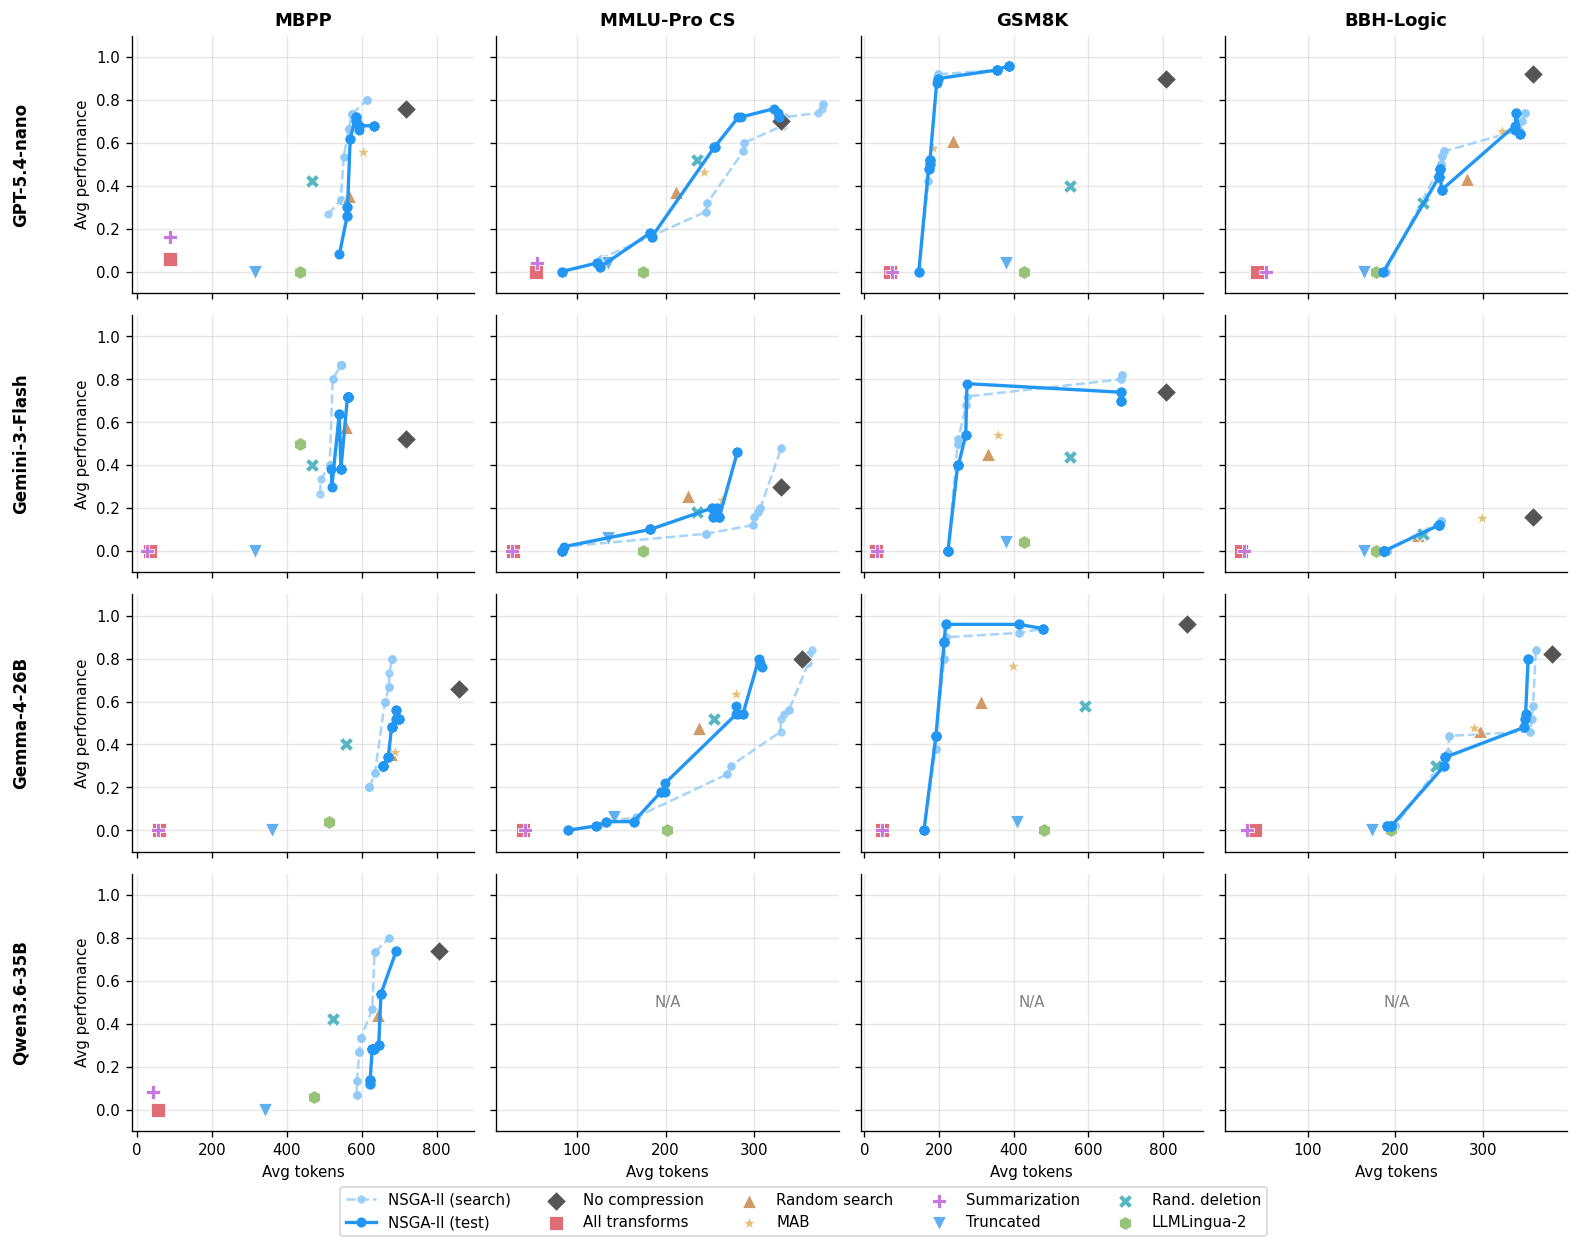

In [32]:
# Helper: extract (tokens, perf) for a list of solutions from JSON
def pareto_xy_json(solutions, split='test'):
    tok  = [s.get(f'{split}_avg_tokens')      or s['search_avg_tokens']      for s in solutions]
    perf = [s.get(f'{split}_avg_performance') or s['search_avg_performance'] for s in solutions]
    return np.array(tok), np.array(perf)

def draw_pareto_front(ax, tokens, perfs, color, label, lw=2, ms=5, ls='-'):
    order = np.argsort(tokens)
    ax.plot(tokens[order], perfs[order], f'o{ls}', color=color, lw=lw,
            markersize=ms, label=label, zorder=6)

def draw_baselines(ax, baselines, split='test'):
    for bl in baselines:
        bname = bl['name']
        if bname not in BASELINE_STYLE:
            continue
        st = BASELINE_STYLE[bname]
        bt = bl.get(f'{split}_avg_tokens')      or bl['search_avg_tokens']
        bp = bl.get(f'{split}_avg_performance') or bl['search_avg_performance']
        ax.scatter(bt, bp, s=80, label=st['label'],
                   color=st['color'], marker=st['marker'],
                   zorder=5, edgecolors='white', linewidths=0.5)


def rq1_grid(task_list, title_suffix='', filename=None):
    available_models = [(lbl, mdir) for lbl, mdir, _ in MODELS
                        if any(stem in RESULTS[mdir] for stem, _, _ in task_list)]
    available_tasks  = [(stem, lbl) for stem, lbl, _ in task_list
                        if any(stem in RESULTS[mdir] for _, mdir, _ in MODELS)]
    if not available_models or not available_tasks:
        print('No data available.')
        return

    nrows, ncols = len(available_models), len(available_tasks)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL2, ROW_H * nrows),
                             squeeze=False,
                             sharey='all', sharex='col')

    legend_handles = {}

    for ri, (mlabel, mdir) in enumerate(available_models):
        for ci, (stem, tlabel) in enumerate(available_tasks):
            ax = axes[ri][ci]
            ax.set_ylim(-0.1, 1.1)
            ax.set_xlabel('Avg tokens' if ri == nrows - 1 else '')
            ax.set_ylabel('Avg performance' if ci == 0 else '')
            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

            d = RESULTS[mdir].get(stem)
            if d is None:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                ax.set_visible(True)
                continue

            # Search pareto front
            stok, sperf = pareto_xy_json(d['pareto_solutions'], split='search')
            h, = ax.plot(*[x[np.argsort(stok)] for x in (stok, sperf)],
                         'o--', color=SEARCH_COLOR, lw=1.5, markersize=4,
                         label='NSGA-II (search)', zorder=5, alpha=0.8)
            legend_handles.setdefault('NSGA-II (search)', h)

            # Test pareto front
            ttok, tperf = pareto_xy_json(d['pareto_solutions'], split='test')
            h, = ax.plot(*[x[np.argsort(ttok)] for x in (ttok, tperf)],
                         'o-', color=NSGA2_COLOR, lw=2, markersize=5,
                         label='NSGA-II (test)', zorder=6)
            legend_handles.setdefault('NSGA-II (test)', h)

            # Baselines on test
            for bl in d['baselines']:
                bname = bl['name']
                if bname not in BASELINE_STYLE:
                    continue
                st = BASELINE_STYLE[bname]
                bt = bl.get('test_avg_tokens')       or bl['search_avg_tokens']
                bp = bl.get('test_avg_performance')  or bl['search_avg_performance']
                h = ax.scatter(bt, bp, s=70, color=st['color'], marker=st['marker'],
                               zorder=5, edgecolors='white', linewidths=0.5,
                               label=st['label'])
                legend_handles.setdefault(st['label'], h)

    handles = list(legend_handles.values())
    labels  = list(legend_handles.keys())
    fig.legend(handles, labels, loc='lower center',
               ncol=min(5, len(labels)),
               bbox_to_anchor=(0.5, -0.04), frameon=True, fontsize=9)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, bbox_inches='tight')
    plt.show()


rq1_grid(COMMON_TASKS, filename='rq1_common.pdf')

---
## RQ2 — How PromptPiper Compares to Existing Baselines

> *How does PromptPiper compare to existing baselines for prompt optimization?*

Distributions of per-example **performance** (left column) and **compressed tokens** (right column)
from the detailed results. Rows correspond to benchmarks. Each method's distribution is shown as a violin.

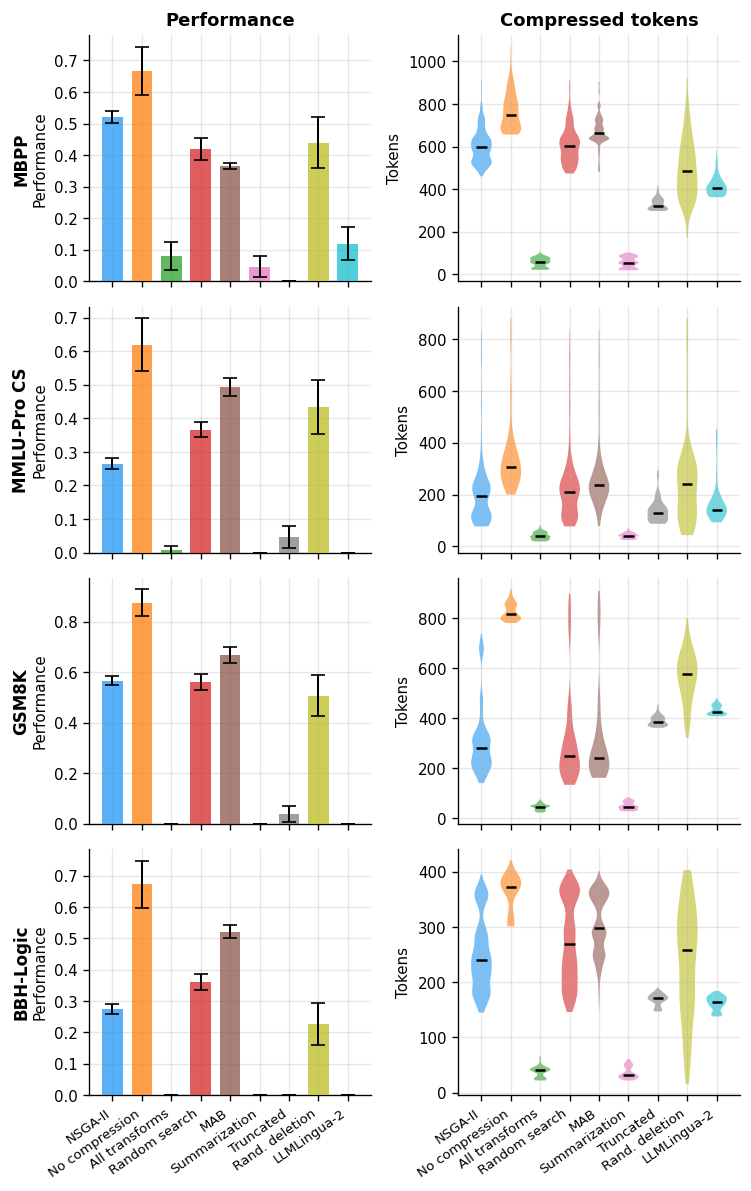

In [38]:
def collect_rq2_data():
    """Collect per-example perf & tokens from detailed results for all models × tasks."""
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            det = DETAILED[mdir].get(stem)
            if det is None:
                continue
            for row in det:
                sol_type = row['solution_type']
                if sol_type == 'pareto':
                    method = 'NSGA-II'
                elif sol_type.startswith('baseline_'):
                    bname = sol_type.replace('baseline_', '')
                    method = BASELINE_STYLE.get(bname, {}).get('label', bname)
                else:
                    continue
                rows.append({
                    'model': mlabel,
                    'task':  tlabel,
                    'method': method,
                    'performance': row['performance'],
                    'compressed_tokens': row['compressed_tokens'],
                })
    return pd.DataFrame(rows)


df_rq2 = collect_rq2_data()

if df_rq2.empty:
    print('No detailed results available for RQ2 plots.')
else:
    tasks_with_data  = [l for _, l, _ in TASKS if l in df_rq2['task'].unique()]
    methods_ordered  = (['NSGA-II']
                        + [st['label'] for st in BASELINE_STYLE.values()
                           if st['label'] in df_rq2['method'].unique()])
    methods_ordered  = list(dict.fromkeys(methods_ordered))

    method_colors = {m: c for m, c in zip(
        methods_ordered,
        plt.cm.tab10(np.linspace(0, 1, len(methods_ordered))))}
    method_colors['NSGA-II'] = NSGA2_COLOR

    nrows = len(tasks_with_data)
    ncols = 2  # performance bar | tokens violin

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL1, ROW_H * nrows), sharex='col', squeeze=False)

    for ri, tlabel in enumerate(tasks_with_data):
        sub = df_rq2[df_rq2['task'] == tlabel]

        for ci, (metric, xlabel) in enumerate([
                ('performance', 'Performance'), ('compressed_tokens', 'Compressed tokens')]):
            ax = axes[ri][ci]
            positions = list(range(len(methods_ordered)))
            data_per_method = [sub[sub['method'] == m][metric].dropna().values
                               for m in methods_ordered]

            if ci == 0:
                # Bar chart with 95% CI for performance
                for pos, (m, data) in enumerate(zip(methods_ordered, data_per_method)):
                    color = method_colors[m]
                    if len(data) == 0:
                        continue
                    mean_val = np.mean(data)
                    ci_val = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data)) if len(data) > 1 else 0
                    ax.bar(pos, mean_val, width=0.7, color=color, alpha=0.75, zorder=3)
                    ax.errorbar(pos, mean_val, yerr=ci_val, fmt='none',
                                color='black', capsize=4, linewidth=1.2, zorder=4)
                ax.set_ylim(bottom=0)
            else:
                # Violin for token distribution
                for pos, (m, data) in enumerate(zip(methods_ordered, data_per_method)):
                    if len(data) == 0:
                        continue
                    color = method_colors[m]
                    parts = ax.violinplot([data], positions=[pos], widths=0.7,
                                          showmedians=True, showextrema=False)
                    for pc in parts['bodies']:
                        pc.set_facecolor(color)
                        pc.set_alpha(0.6)
                    parts['cmedians'].set_color('black')
                    parts['cmedians'].set_linewidth(1.5)

            ax.set_xticks(positions)
            ax.set_xticklabels(methods_ordered, rotation=35, ha='right', fontsize=8)
            ax.set_ylabel(xlabel if ci == 0 else 'Tokens')
            if ri == 0:
                ax.set_title(xlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(tlabel, xy=(-0.275, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq2_distributions.pdf', bbox_inches='tight')
    plt.show()

---
## RQ3 — Cost and Convergence Characteristics

> *What are the cost and convergence characteristics of different optimization strategies?*

### RQ3.1 — Cumulative search + test time per approach

Box plots showing the distribution of total elapsed time (search + evaluation) across
available runs, broken down by model and benchmark.

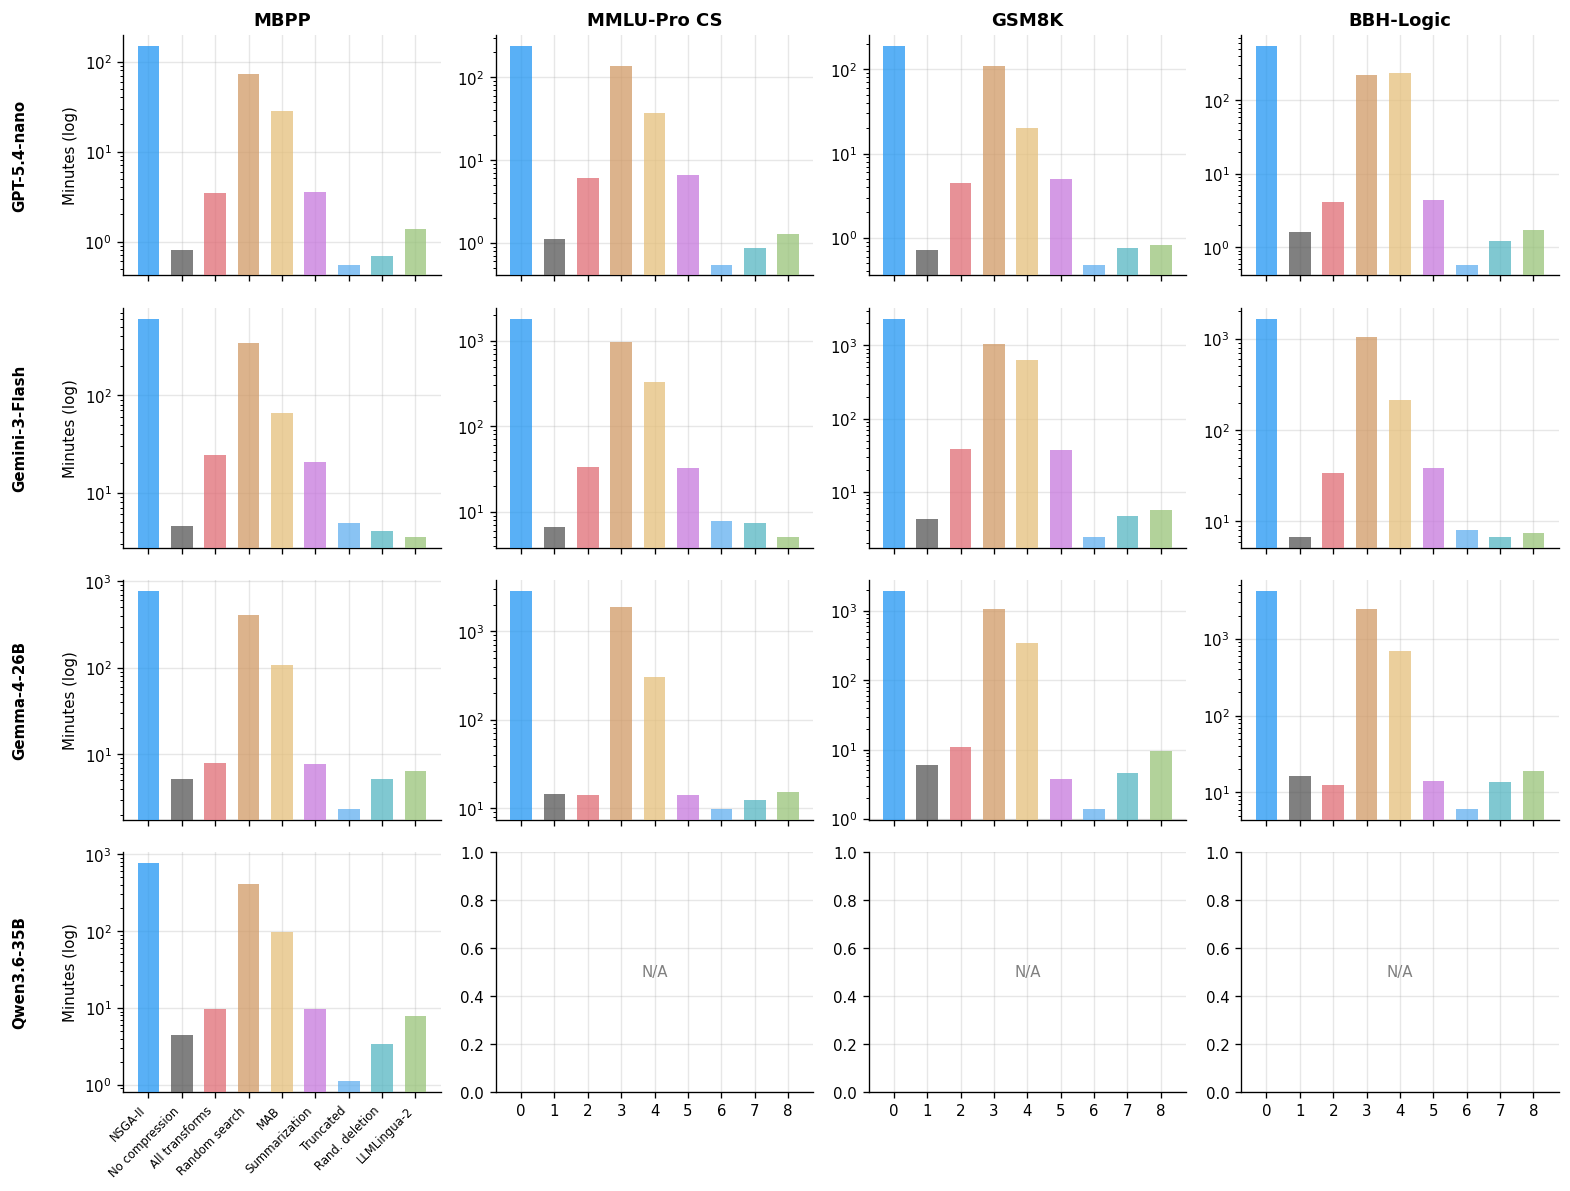

In [39]:
def collect_timing():
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            rows.append({
                'model': mlabel, 'task': tlabel,
                'approach': 'NSGA-II',
                'total_seconds': d['search_elapsed_seconds'] + d['eval_elapsed_seconds'],
            })
            for bl in d['baselines']:
                bname = bl['name']
                label = BASELINE_STYLE.get(bname, {}).get('label', bname)
                rows.append({
                    'model': mlabel, 'task': tlabel,
                    'approach': label,
                    'total_seconds': bl.get('elapsed_seconds', np.nan),
                })
    return pd.DataFrame(rows)


df_time = collect_timing()

if df_time.empty:
    print('No timing data available.')
else:
    df_time['total_minutes'] = df_time['total_seconds'] / 60

    approaches = (['NSGA-II']
                  + [st['label'] for st in BASELINE_STYLE.values()
                     if st['label'] in df_time['approach'].unique()])
    approaches = list(dict.fromkeys(approaches))

    app_colors = ([NSGA2_COLOR]
                  + [BASELINE_STYLE[k]['color']
                     for k in BASELINE_STYLE
                     if BASELINE_STYLE[k]['label'] in approaches[1:]])

    models_present = [lbl for lbl, _, _ in MODELS if lbl in df_time['model'].unique()]
    tasks_present  = [lbl for _, lbl, _ in TASKS
                      if lbl != 'MuSR' and lbl in df_time['task'].unique()]

    nrows = len(models_present)
    ncols = len(tasks_present)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL2, ROW_H * nrows),
                             squeeze=False, sharex='col')

    x = np.arange(len(approaches))
    width = 0.65

    for ri, mlabel in enumerate(models_present):
        for ci, tlabel in enumerate(tasks_present):
            ax = axes[ri][ci]
            sub = df_time[(df_time['model'] == mlabel) & (df_time['task'] == tlabel)]

            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=9, fontweight='bold', rotation=90, va='center')
                ax.set_ylabel('Minutes (log)')

            if sub.empty:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                continue

            for pos, (appr, color) in enumerate(zip(approaches, app_colors)):
                val = sub[sub['approach'] == appr]['total_minutes'].dropna().values
                if len(val) == 0 or np.isnan(val[0]):
                    continue
                ax.bar(pos, val[0], width, color=color, alpha=0.75, zorder=3)

            ax.set_xticks(x)
            if ri == nrows - 1:
                ax.set_xticklabels(approaches, rotation=45, ha='right', fontsize=7)
            ax.set_yscale('log')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_1_timing.pdf', bbox_inches='tight')
    plt.show()

### RQ3.2 — Time distribution across models (per task)

Box plots showing how each approach's total time varies across models, aggregated per task.

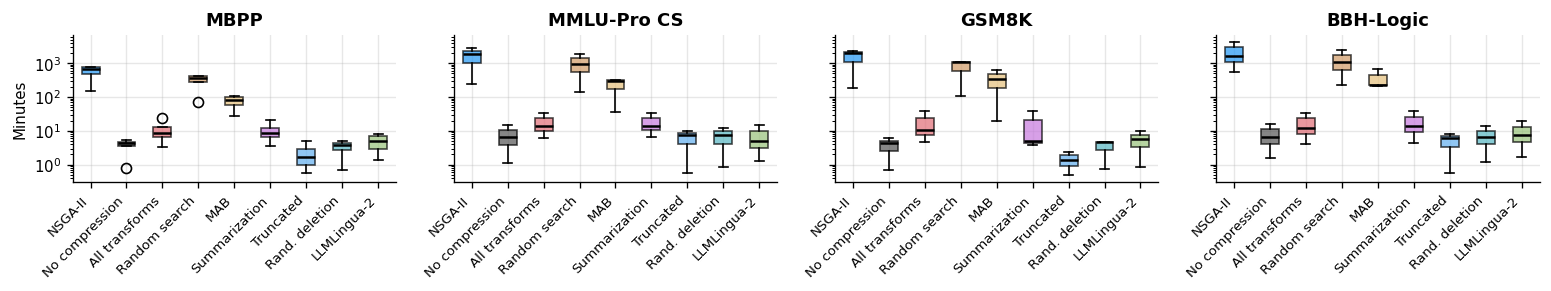

In [40]:
if df_time.empty:
    print('No timing data available.')
else:
    tasks_present  = [lbl for _, lbl, _ in TASKS
                      if lbl != 'MuSR' and lbl in df_time['task'].unique()]
    approaches_avail = list(dict.fromkeys(
        ['NSGA-II'] + [st['label'] for st in BASELINE_STYLE.values()
                        if st['label'] in df_time['approach'].unique()]))

    ncols = len(tasks_present)
    fig, axes = plt.subplots(1, ncols, figsize=(COL2, ROW_H), squeeze=False, sharey=True)

    for ci, tlabel in enumerate(tasks_present):
        ax = axes[0][ci]
        sub = df_time[df_time['task'] == tlabel]
        data = [sub[sub['approach'] == a]['total_minutes'].dropna().values
                for a in approaches_avail]
        bp = ax.boxplot([d if len(d) else [np.nan] for d in data],
                        labels=approaches_avail, patch_artist=True,
                        medianprops=dict(color='black', lw=1.5))
        colors_bl = ([NSGA2_COLOR]
                     + [BASELINE_STYLE[k]['color']
                        for k in BASELINE_STYLE
                        if BASELINE_STYLE[k]['label'] in approaches_avail[1:]])
        for patch, color in zip(bp['boxes'], colors_bl[:len(bp['boxes'])]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_title(tlabel, fontweight='bold')
        ax.set_xticklabels(approaches_avail, rotation=45, ha='right', fontsize=8)
        ax.set_ylabel('Minutes' if ci == 0 else '')
        ax.set_yscale('log')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_2_timing_boxplots.pdf', bbox_inches='tight')
    plt.show()

### RQ3.3 — Convergence: aggregated per task, averaged across models

Lines show the mean best performance and mean minimum tokens across models. Shaded regions show ±1 standard deviation.

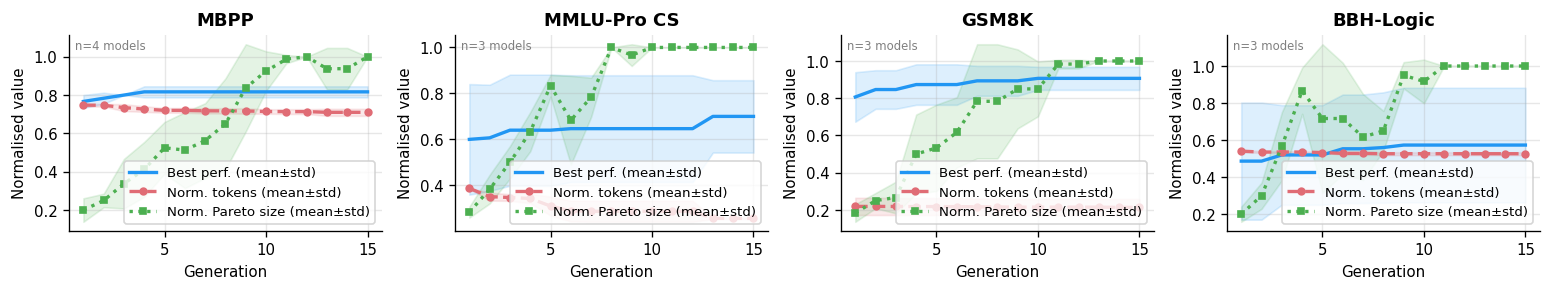

In [41]:
def collect_convergence():
    """Return dict task_label -> list of {model, history, no_compression_tokens}."""
    out = defaultdict(list)
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            history = d.get('generation_history', [])
            if not history:
                continue
            # No-compression token count for normalization
            ref = next((b for b in d['baselines'] if b['name'] == 'no_compression'), None)
            ref_tokens = (ref.get('test_avg_tokens') or ref.get('search_avg_tokens', 1)
                          if ref else 1)
            out[tlabel].append({'model': mlabel, 'history': history,
                                'ref_tokens': ref_tokens})
    return out


conv_data = collect_convergence()

if not conv_data:
    print('No generation history data available.')
else:
    tasks_conv = list(conv_data.keys())
    ncols = min(4, len(tasks_conv))
    nrows = (len(tasks_conv) + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL2, ROW_H * nrows), squeeze=False)

    for idx, tlabel in enumerate(tasks_conv):
        ax = axes[idx // ncols][idx % ncols]
        entries = conv_data[tlabel]

        n_gens = max(h['history'][-1]['generation'] for h in entries)
        gens = list(range(1, n_gens + 1))

        all_best_perf  = []
        all_norm_tok   = []
        all_norm_pareto = []

        for entry in entries:
            gen_map = {h['generation']: h for h in entry['history']}
            ref_tok = max(entry['ref_tokens'], 1)
            # Max pareto size across all gens for normalization
            max_n = max((gen_map[g]['n_solutions'] for g in gens if g in gen_map), default=1)
            max_n = max(max_n, 1)

            bp_series, nt_series, np_series = [], [], []
            for g in gens:
                h = gen_map.get(g)
                if h and h['pareto_front']:
                    bp_series.append(max(s['avg_performance'] for s in h['pareto_front']))
                    nt_series.append(min(s['avg_tokens'] for s in h['pareto_front']) / ref_tok)
                    np_series.append(h['n_solutions'] / max_n)
                else:
                    bp_series.append(np.nan)
                    nt_series.append(np.nan)
                    np_series.append(np.nan)
            all_best_perf.append(bp_series)
            all_norm_tok.append(nt_series)
            all_norm_pareto.append(np_series)

        def plot_mean_std(ax, gens, data, color, label, ls='-', marker=None):
            arr = np.array(data, dtype=float)
            mean = np.nanmean(arr, axis=0)
            std  = np.nanstd(arr, axis=0)
            ax.plot(gens, mean, color=color, lw=2, ls=ls, label=label,
                    marker=marker, markersize=4, markevery=max(1, len(gens)//10))
            ax.fill_between(gens, mean - std, mean + std, color=color, alpha=0.15)

        plot_mean_std(ax, gens, all_best_perf,  '#2196F3', 'Best perf. (mean±std)')
        plot_mean_std(ax, gens, all_norm_tok,   '#e06c75', 'Norm. tokens (mean±std)',  ls='--', marker='o')
        plot_mean_std(ax, gens, all_norm_pareto,'#4caf50', 'Norm. Pareto size (mean±std)', ls=':', marker='s')

        ax.set_xlabel('Generation')
        ax.set_ylabel('Normalised value')
        ax.set_title(tlabel, fontweight='bold')
        ax.legend(fontsize=8, loc='lower right')
        ax.annotate(f'n={len(entries)} models', xy=(0.02, 0.98), xycoords='axes fraction',
                    fontsize=7, va='top', color='gray')

    for idx in range(len(tasks_conv), nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_3_convergence.pdf', bbox_inches='tight')
    plt.show()

---
## RQ4 — Patterns in Compression Strategies and Transferability

> *What patterns emerge in prompt compression strategies and how transferable are they across datasets?*

### RQ4.1 — Transferred Pareto fronts

Each subplot shows the native Pareto front (blue) alongside the transferred solutions from another task (orange). The grey diamond is the no-compression reference.

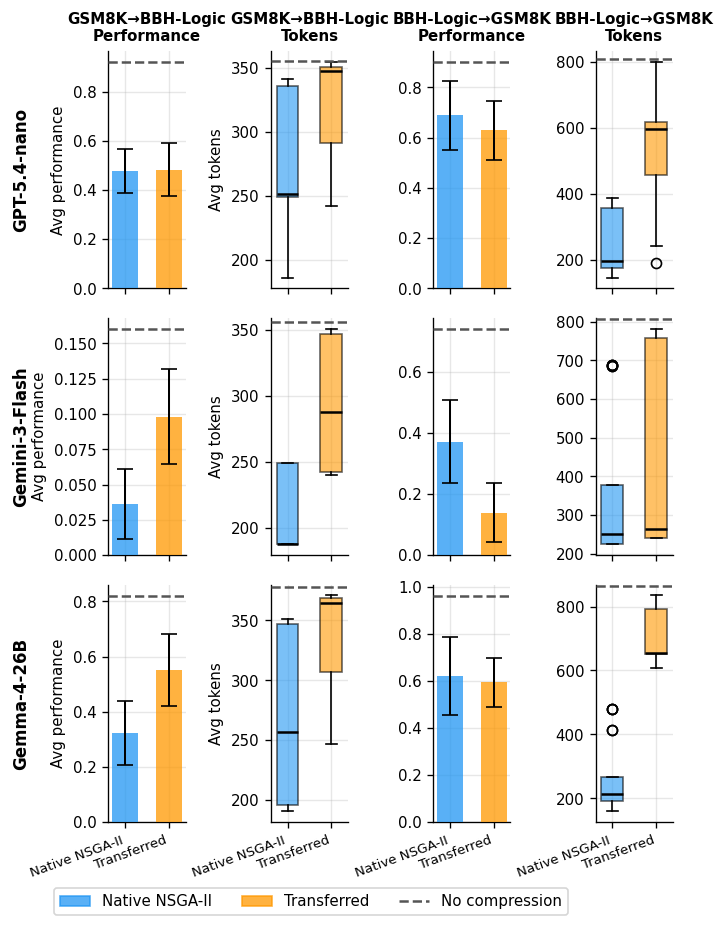

In [49]:
TASK_LABEL_MAP = {stem: lbl for stem, lbl, _ in TASKS}

def rq4_transfer_grid(filename=None):
    models_with_transfer = [
        (lbl, mdir) for lbl, mdir, _ in MODELS
        if any(f'transfer_{s}_to_{t}' in RESULTS[mdir] for s, t in TRANSFER_PAIRS)
    ]
    if not models_with_transfer:
        print('No transfer results available.')
        return

    pairs_avail = list(dict.fromkeys(
        (s, t) for s, t in TRANSFER_PAIRS
        for _, mdir in models_with_transfer
        if f'transfer_{s}_to_{t}' in RESULTS[mdir]
    ))

    nrows = len(models_with_transfer)
    # Each pair has 2 sub-columns: [perf bar, token dist]
    ncols = 2 * len(pairs_avail)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL1, ROW_H * nrows),
                             squeeze=False, sharex='all')

    bar_labels  = ['Native NSGA-II', 'Transferred']
    bar_colors  = [NSGA2_COLOR, '#FF9800']
    x_positions = [0, 1]

    for ri, (mlabel, mdir) in enumerate(models_with_transfer):
        is_bottom_row = (ri == nrows - 1)
        for pi, (src, tgt) in enumerate(pairs_avail):
            src_lbl = TASK_LABEL_MAP.get(src, src)
            tgt_lbl = TASK_LABEL_MAP.get(tgt, tgt)
            col_perf = pi * 2
            col_tok  = pi * 2 + 1
            ax_perf  = axes[ri][col_perf]
            ax_tok   = axes[ri][col_tok]

            if ri == 0:
                ax_perf.set_title(f'{src_lbl}→{tgt_lbl}\nPerformance', fontweight='bold', fontsize=9)
                ax_tok.set_title(f'{src_lbl}→{tgt_lbl}\nTokens', fontweight='bold', fontsize=9)
            if pi == 0:
                ax_perf.annotate(mlabel, xy=(-1.25, 0.5), xycoords='axes fraction',
                                 fontsize=10, fontweight='bold', rotation=90, va='center')

            key = f'transfer_{src}_to_{tgt}'
            tr  = RESULTS[mdir].get(key)
            nat = RESULTS[mdir].get(tgt)

            if tr is None:
                for ax in (ax_perf, ax_tok):
                    ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                            ha='center', va='center', color='gray')
                continue

            # Gather per-solution performance and token data
            nat_perfs = np.array([s.get('test_avg_performance') or s['search_avg_performance']
                                  for s in nat['pareto_solutions']]) if nat else np.array([])
            nat_toks  = np.array([s.get('test_avg_tokens') or s['search_avg_tokens']
                                  for s in nat['pareto_solutions']]) if nat else np.array([])
            tr_perfs  = np.array([s.get('test_avg_performance') or s['search_avg_performance']
                                  for s in tr['solutions']])
            tr_toks   = np.array([s.get('test_avg_tokens') or s['search_avg_tokens']
                                  for s in tr['solutions']])

            # No-compression reference
            nc_perf   = None
            nc_tokens = None
            if nat:
                ref = next((b for b in nat['baselines'] if b['name'] == 'no_compression'), None)
                if ref:
                    nc_perf   = ref.get('test_avg_performance') or ref['search_avg_performance']
                    nc_tokens = ref.get('test_avg_tokens')       or ref['search_avg_tokens']

            # ── Left: performance bar chart with 95% CI ───────────────────
            for pos, (label, data) in zip(x_positions, zip(bar_labels, [nat_perfs, tr_perfs])):
                if len(data) == 0:
                    continue
                mean_val = np.mean(data)
                ci_val = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data)) if len(data) > 1 else 0
                ax_perf.bar(pos, mean_val, width=0.6, color=bar_colors[pos], alpha=0.75,
                            zorder=3)
                ax_perf.errorbar(pos, mean_val, yerr=ci_val, fmt='none',
                                 color='black', capsize=5, linewidth=1.2, zorder=4)

            if nc_perf is not None:
                ax_perf.axhline(nc_perf, color='#555555', lw=1.5, ls='--', zorder=5)

            ax_perf.set_xticks(x_positions)
            ax_perf.set_ylabel('Avg performance' if pi == 0 else '')
            ax_perf.set_ylim(bottom=0)
            if is_bottom_row:
                ax_perf.set_xticklabels(bar_labels, rotation=20, ha='right', fontsize=8)

            # ── Right: token distribution box plot (positions match bar chart) ──
            tok_data   = [d for d in [nat_toks, tr_toks] if len(d) > 0]
            tok_labels_present = [l for l, d in zip(bar_labels, [nat_toks, tr_toks]) if len(d) > 0]
            tok_colors = [c for c, d in zip(bar_colors, [nat_toks, tr_toks]) if len(d) > 0]
            tok_positions = [p for p, d in zip(x_positions, [nat_toks, tr_toks]) if len(d) > 0]

            if tok_data:
                bp = ax_tok.boxplot(tok_data, positions=tok_positions,
                                    widths=0.5, patch_artist=True,
                                    medianprops=dict(color='black', lw=1.5),
                                    manage_ticks=False)
                for patch, color in zip(bp['boxes'], tok_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.6)

            if nc_tokens is not None:
                ax_tok.axhline(nc_tokens, color='#555555', lw=1.5, ls='--', zorder=5)

            ax_tok.set_xticks(x_positions)
            ax_tok.set_ylabel('Avg tokens' if pi == 0 else '')
            if is_bottom_row:
                ax_tok.set_xticklabels(tok_labels_present, rotation=20, ha='right', fontsize=8)

    # Shared legend
    legend_elements = [
        plt.Rectangle((0, 0), 1, 1, color=NSGA2_COLOR, alpha=0.75, label='Native NSGA-II'),
        plt.Rectangle((0, 0), 1, 1, color='#FF9800',   alpha=0.75, label='Transferred'),
        plt.Line2D([0], [0], color='#555555', lw=1.5, ls='--', label='No compression'),
    ]
    fig.legend(handles=legend_elements, loc='lower center', ncol=3,
               bbox_to_anchor=(0.5, -0.03), frameon=True, fontsize=9)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, bbox_inches='tight')
    plt.show()


rq4_transfer_grid(filename='rq4_1_transfer.pdf')

### RQ4.2 — Operator usage in Pareto-optimal solutions

Bar chart showing average operator frequency in Pareto-optimal solutions across all models (excluding MuSR),
split by prompt section (`instruction` / `shots` — one subplot per section).
Operator names are taken from `transformation_names` (the correct field, derived directly from the
problem's operator list). Operators are sorted by decreasing overall mean frequency within each section.
The overlaid line with markers tracks the overall mean frequency across tasks.

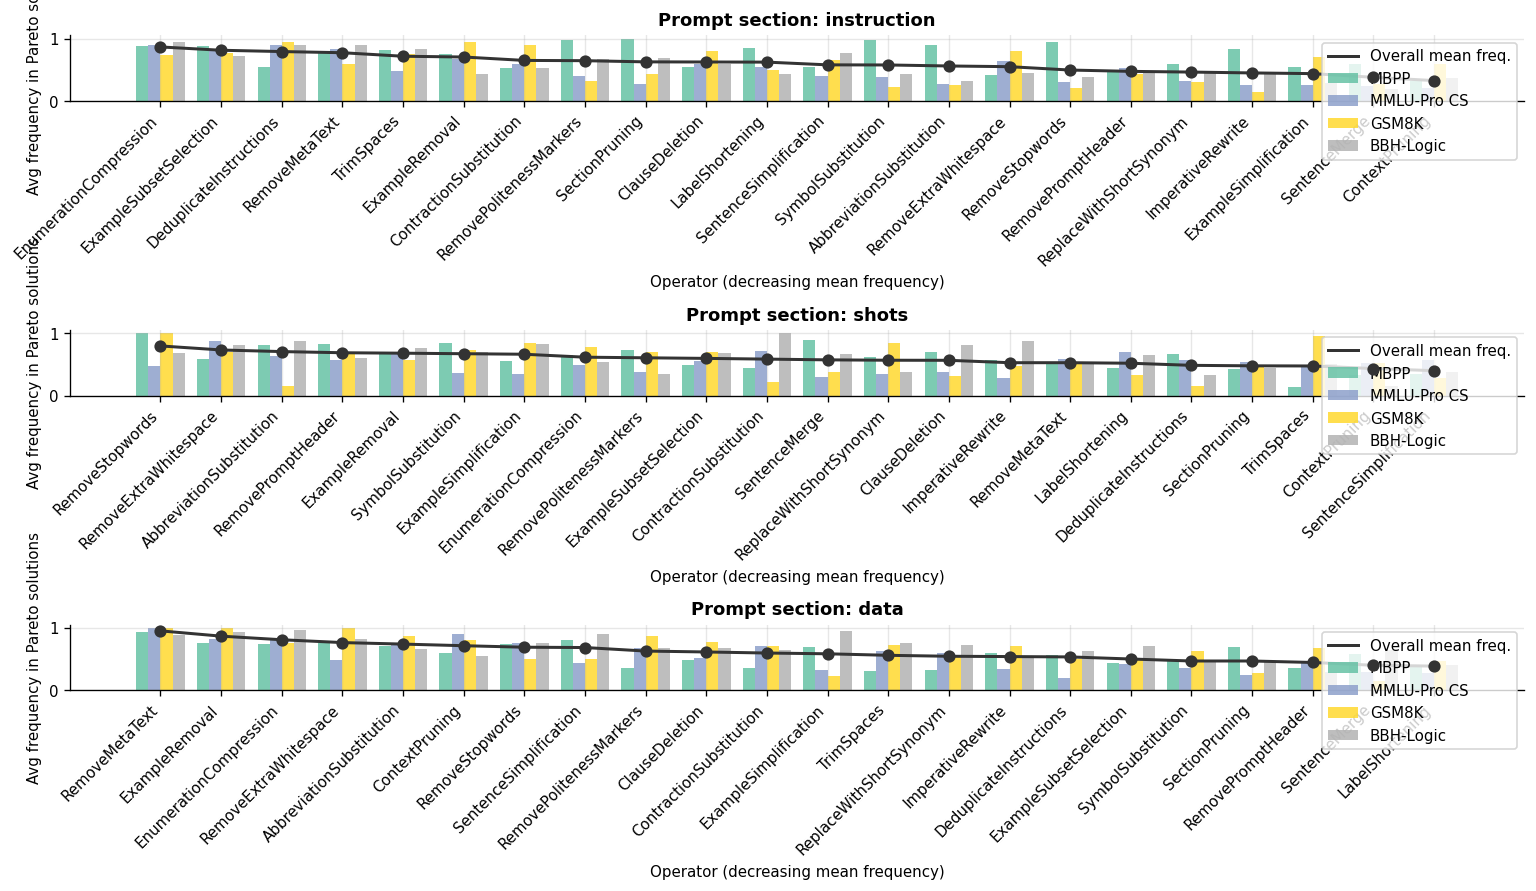

In [50]:
_SECTION_PREFIX = {'I': 'instruction', 'S': 'shots', 'D': 'data'}


def collect_operator_usage():
    """Return DataFrame with columns [model, task, operator, section, frequency].

    Excludes MuSR. Uses transformation_names (correct field) rather than
    transformation_ids (which has a labelling bug). Section is derived from the
    I:/S:/D: prefix; entries without a prefix are labelled 'flat'.
    Frequency = number of solutions containing (operator, section) / total solutions.
    """
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            sols = d['pareto_solutions']
            if not sols:
                continue

            op_section_counts = Counter()
            for sol in sols:
                for name in sol.get('transformation_names', []):
                    if ':' in name:
                        prefix, op_name = name.split(':', 1)
                        section = _SECTION_PREFIX.get(prefix, 'flat')
                    else:
                        op_name = name
                        section = 'flat'
                    op_section_counts[(op_name, section)] += 1

            for (op, section), cnt in op_section_counts.items():
                rows.append({
                    'model':     mlabel,
                    'task':      tlabel,
                    'operator':  op,
                    'section':   section,
                    'frequency': cnt / len(sols),
                })
    return pd.DataFrame(rows)


df_ops = collect_operator_usage()

if df_ops.empty:
    print('No operator usage data available.')
else:
    section_order    = ['instruction', 'shots', 'data', 'flat']
    sections_present = [s for s in section_order if s in df_ops['section'].unique()]

    fig, axes = plt.subplots(
        len(sections_present), 1,
        figsize=(COL2, ROW_H * len(sections_present)),
        squeeze=False,
    )

    for gi, section in enumerate(sections_present):
        ax     = axes[gi][0]
        df_grp = df_ops[df_ops['section'] == section]

        tasks_present   = [lbl for _, lbl, _ in TASKS
                           if lbl != 'MuSR' and lbl in df_grp['task'].unique()]
        task_colors_map = {t: c for t, c in zip(
            tasks_present, plt.cm.Set2(np.linspace(0, 1, max(len(tasks_present), 1))))}

        agg   = df_grp.groupby(['operator', 'task'])['frequency'].mean().reset_index()
        pivot = (agg.pivot(index='operator', columns='task', values='frequency')
                 .reindex(columns=tasks_present, fill_value=0))

        overall_mean        = df_grp.groupby('operator')['frequency'].mean()
        all_ops_sorted      = overall_mean.sort_values(ascending=False).index.tolist()
        pivot               = pivot.reindex(index=all_ops_sorted, fill_value=0)
        overall_mean_sorted = overall_mean.reindex(all_ops_sorted, fill_value=0).values

        x     = np.arange(len(all_ops_sorted))
        width = 0.8 / max(len(tasks_present), 1)

        for i, task in enumerate(tasks_present):
            ax.bar(x + i * width, pivot[task].values, width,
                   label=task, color=task_colors_map[task], alpha=0.85)

        x_center = x + width * (len(tasks_present) - 1) / 2
        ax.plot(x_center, overall_mean_sorted, color='#333333', lw=1.8, zorder=5,
                label='Overall mean freq.')
        for xi, yi in zip(x_center, overall_mean_sorted):
            ax.scatter(xi, yi, color='#333333', s=40, zorder=6,
                       marker='o')

        ax.set_xticks(x_center)
        ax.set_xticklabels(all_ops_sorted, rotation=45, ha='right', fontsize=9)
        ax.set_ylabel('Avg frequency in Pareto solutions')
        ax.set_xlabel('Operator (decreasing mean frequency)')
        ax.legend(loc='upper right', fontsize=9)
        ax.set_title(f'Prompt section: {section}', fontweight='bold')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq4_2_operators.pdf', bbox_inches='tight')
    plt.show()